# 02 — Exploratory Data Analysis & Statistical Reasoning

Decision-oriented EDA on the cleaned dataset. Every chart answers a specific business question; counts and percentages are shown together so magnitude is never hidden behind proportions. Statistical tests (Phase 3) are used only where they add evidence to a business question.

**Language rule:** findings are stated as *association / predictive signal*, never as causation — this dataset is observational and cannot support causal claims.

In [1]:
import sys
from pathlib import Path

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(p for p in _candidates if (p / "src").exists())
sys.path.insert(0, str(PROJECT_ROOT))
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.data.clean import load_raw, clean_telco

sns.set_theme(style="whitegrid")
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load through the same cleaning path as notebook 01 (deterministic, no side effects).
df = clean_telco(load_raw())[0]
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)


def churn_table(by):
    """Churn counts and churn rate grouped by one column, sorted by churn rate."""
    t = df.groupby(by, observed=True)["churn_flag"].agg(customers="count", churners="sum")
    t["churn_rate"] = t["churners"] / t["customers"]
    return t.sort_values("churn_rate", ascending=False)


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


## 1. Overall churn rate

**Business question:** how big is the churn problem overall?

In [2]:
overall = df['churn_flag'].agg(customers='count', churners='sum')
overall['churn_rate'] = overall['churners'] / overall['customers']
print(overall)
print(f"\nOverall churn rate: {overall['churn_rate']:.1%} ({int(overall['churners'])} of {int(overall['customers'])} customers)")

customers     7043.00000
churners      1869.00000
churn_rate       0.26537
Name: churn_flag, dtype: float64

Overall churn rate: 26.5% (1869 of 7043 customers)


## 2. Churn by contract type

**Business question:** which contract types bleed the most customers?

                customers  churners  churn_rate
Contract                                       
Month-to-month       3875      1655    0.427097
One year             1473       166    0.112695
Two year             1695        48    0.028319


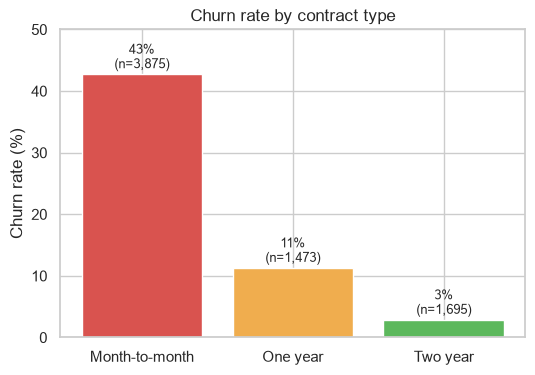

In [3]:
t = churn_table('Contract')
print(t)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(t.index, t['churn_rate'] * 100, color=['#d9534f', '#f0ad4e', '#5cb85c'])
for b, n in zip(bars, t['customers']):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f'{b.get_height():.0f}%\n(n={n:,})', ha='center', fontsize=9)
ax.set(ylabel='Churn rate (%)', title='Churn rate by contract type')
ax.set_ylim(0, 50)
savefig(fig, 'churn_by_contract.png')
plt.show()

## 3. Churn by tenure

**Business question:** when in the customer lifecycle does churn happen?

             customers  churners  churn_rate
tenure_band                                 
0-6 mo            1481       784    0.529372
7-12 mo            705       253    0.358865
13-24 mo          1024       294    0.287109
25-48 mo          1594       325    0.203890
49-72 mo          2239       213    0.095132


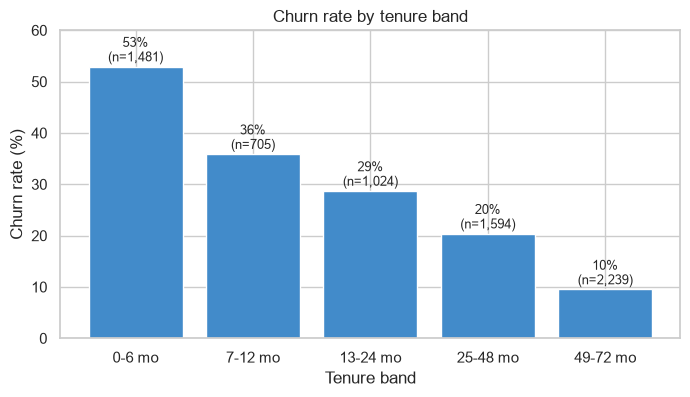

In [4]:
tenure_bins = [0, 6, 12, 24, 48, 72]
tenure_labels = ['0-6 mo', '7-12 mo', '13-24 mo', '25-48 mo', '49-72 mo']
df['tenure_band'] = pd.cut(df['tenure'], bins=tenure_bins, labels=tenure_labels, right=True, include_lowest=True)
t = churn_table('tenure_band')
print(t)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(t.index.astype(str), t['churn_rate'] * 100, color='#428bca')
ax.set(ylabel='Churn rate (%)', xlabel='Tenure band', title='Churn rate by tenure band')
for x, (rate, n) in enumerate(zip(t['churn_rate'], t['customers'])):
    ax.text(x, rate * 100 + 1, f'{rate:.0%}\n(n={n:,})', ha='center', fontsize=9)
ax.set_ylim(0, 60)
savefig(fig, 'churn_by_tenure.png')
plt.show()

## 4. Churn by payment method & billing

**Business question:** do billing mechanics relate to churn?

                           customers  churners  churn_rate
PaymentMethod                                             
Electronic check                2365      1071    0.452854
Mailed check                    1612       308    0.191067
Bank transfer (automatic)       1544       258    0.167098
Credit card (automatic)         1522       232    0.152431


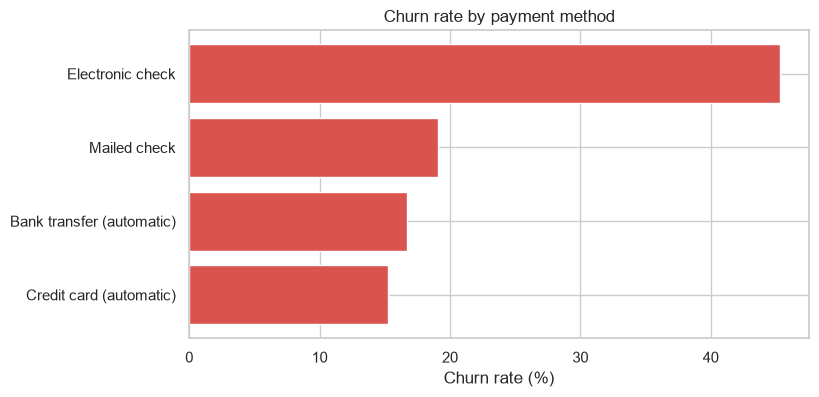

In [5]:
t = churn_table('PaymentMethod')
print(t)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(t.index[::-1], t['churn_rate'][::-1] * 100, color='#d9534f')
ax.set(xlabel='Churn rate (%)', title='Churn rate by payment method')
savefig(fig, 'churn_by_payment.png')
plt.show()

In [6]:
t = churn_table('PaperlessBilling')
print(t)

                  customers  churners  churn_rate
PaperlessBilling                                 
Yes                    4171      1400    0.335651
No                     2872       469    0.163301


## 5. Churn by internet service & add-on services

**Business question:** which services are associated with churn — and do add-ons protect against it?

In [7]:
t = churn_table('InternetService')
print(t)

                 customers  churners  churn_rate
InternetService                                 
Fiber optic           3096      1297    0.418928
DSL                   2421       459    0.189591
No                    1526       113    0.074050


has_service          No    Yes
service                       
DeviceProtection  0.391  0.225
OnlineBackup      0.399  0.215
OnlineSecurity    0.418  0.146
StreamingMovies   0.337  0.299
StreamingTV       0.335  0.301
TechSupport       0.416  0.152


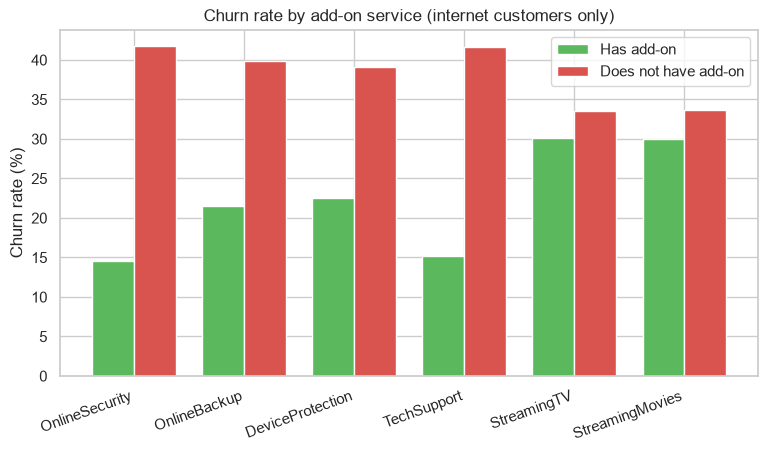

In [8]:
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
rows = []
for col in addon_cols:
    sub = df[df['InternetService'] != 'No']  # add-ons only exist for internet customers
    for value in ['Yes', 'No']:
        grp = sub[sub[col] == value]
        rows.append({'service': col, 'has_service': value, 'customers': len(grp), 'churn_rate': grp['churn_flag'].mean()})
services = pd.DataFrame(rows)
print(services.pivot(index='service', columns='has_service', values='churn_rate').round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
idx = np.arange(len(addon_cols))
w = 0.38
yes = services[services['has_service'] == 'Yes'].set_index('service').loc[addon_cols, 'churn_rate']
no = services[services['has_service'] == 'No'].set_index('service').loc[addon_cols, 'churn_rate']
ax.bar(idx - w / 2, yes * 100, w, label='Has add-on', color='#5cb85c')
ax.bar(idx + w / 2, no * 100, w, label='Does not have add-on', color='#d9534f')
ax.set_xticks(idx, addon_cols, rotation=20, ha='right')
ax.set(ylabel='Churn rate (%)', title='Churn rate by add-on service (internet customers only)')
ax.legend()
savefig(fig, 'churn_by_addons.png')
plt.show()

## 6. Churn by monthly & total charges

**Business question:** is churn concentrated among high-paying customers?

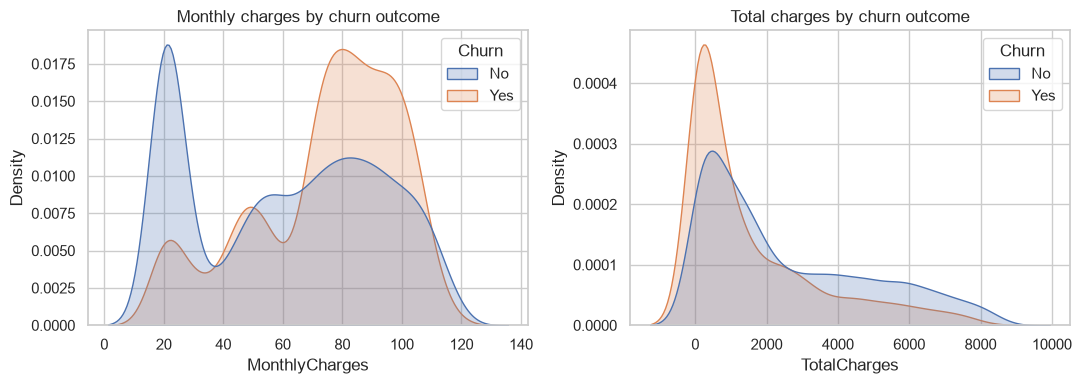

       MonthlyCharges  TotalCharges
Churn                              
No              61.27       2549.91
Yes             74.44       1531.80


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, fill=True, ax=axes[0])
axes[0].set_title('Monthly charges by churn outcome')
sns.kdeplot(data=df, x='TotalCharges', hue='Churn', common_norm=False, fill=True, ax=axes[1])
axes[1].set_title('Total charges by churn outcome')
plt.tight_layout()
savefig(fig, 'charges_by_churn.png')
plt.show()

print(df.groupby('Churn', observed=True)[['MonthlyCharges', 'TotalCharges']].mean().round(2))

In [10]:
# Monthly-charge bands
charge_bins = [0, 35, 55, 75, 95, 200]
charge_labels = ['<=35', '35-55', '55-75', '75-95', '95+']
df['charge_band'] = pd.cut(df['MonthlyCharges'], bins=charge_bins, labels=charge_labels)
t = churn_table('charge_band')
print(t)

             customers  churners  churn_rate
charge_band                                 
75-95             1825       663    0.363288
95+               1295       418    0.322780
35-55              897       251    0.279822
55-75             1291       348    0.269558
<=35              1735       189    0.108934


## 7. Churn by demographics

**Business question:** do churn rates differ across customer demographics (useful for targeting, even if weakly)?

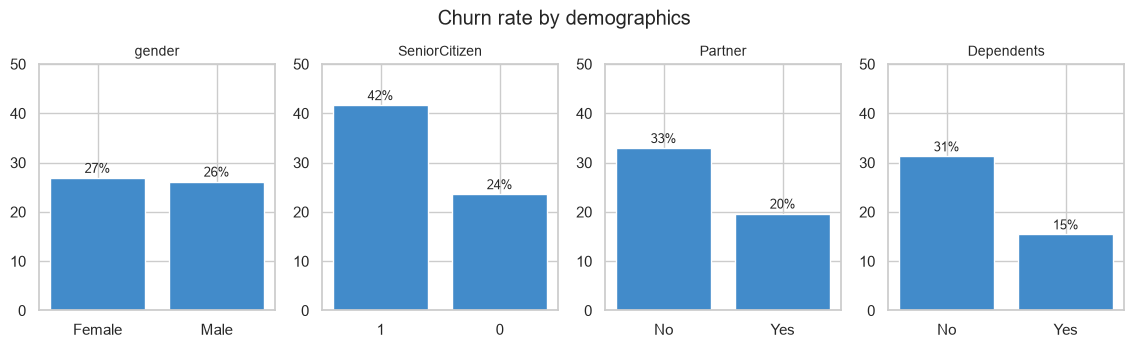

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, col in zip(axes, ['gender', 'SeniorCitizen', 'Partner', 'Dependents']):
    t = churn_table(col)
    ax.bar(t.index.astype(str), t['churn_rate'] * 100, color='#428bca')
    ax.set_title(col, fontsize=10)
    ax.set_ylim(0, 50)
    for x, rate in enumerate(t['churn_rate']):
        ax.text(x, rate * 100 + 1, f'{rate:.0%}', ha='center', fontsize=9)
plt.suptitle('Churn rate by demographics', y=1.05)
savefig(fig, 'churn_by_demographics.png')
plt.show()

## 8. Service bundles & service count

**Business question:** do customers with more services churn less (stickiness)?

             customers  churners  churn_rate
addon_count                                 
0                  693       362    0.522367
1                  966       442    0.457557
2                 1033       370    0.358180
3                 1118       306    0.273703
4                  852       190    0.223005
5                  571        71    0.124343
6                  284        15    0.052817


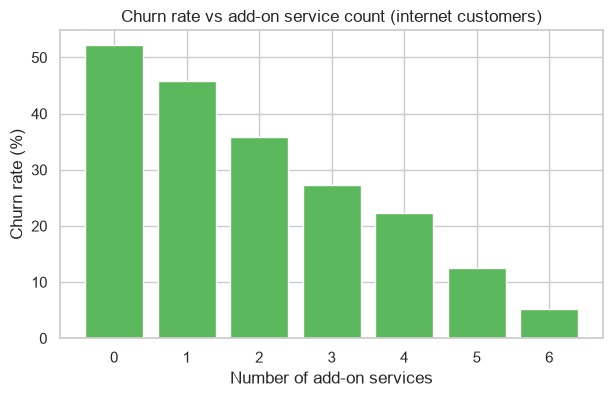

internet service mix for internet customers:
InternetService
Fiber optic    3096
DSL            2421
Name: count, dtype: int64


In [12]:
# Count of add-on services owned (internet customers only; phone is near-universal)
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
internet = df[df['InternetService'] != 'No'].copy()
internet['addon_count'] = (internet[addon_cols] == 'Yes').sum(axis=1)
t = internet.groupby('addon_count')['churn_flag'].agg(customers='count', churners='sum')
t['churn_rate'] = t['churners'] / t['customers']
print(t)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(t.index.astype(str), t['churn_rate'] * 100, color='#5cb85c')
ax.set(xlabel='Number of add-on services', ylabel='Churn rate (%)', title='Churn rate vs add-on service count (internet customers)')
savefig(fig, 'churn_by_addon_count.png')
plt.show()

print('internet service mix for internet customers:')
print(internet['InternetService'].value_counts())

## 9. High-value customers & high-revenue/high-churn segments

**Business question:** where is the most monthly revenue concentrated, and how exposed is it to churn?

In [13]:
# Value definition: monthly revenue contribution (MonthlyCharges). Top quartile = high value.
q75 = df['MonthlyCharges'].quantile(0.75)
df['high_value'] = df['MonthlyCharges'] >= q75
print('high-value cutoff (75th pct of MonthlyCharges):', round(q75, 2))

seg = df.groupby('high_value')['churn_flag'].agg(customers='count', churners='sum')
seg['churn_rate'] = seg['churners'] / seg['customers']
seg['monthly_revenue'] = df.groupby('high_value')['MonthlyCharges'].sum()
seg['monthly_revenue_at_risk_proxy'] = seg['monthly_revenue'] * seg['churn_rate']
print(seg)

revenue = df.groupby('Contract')['MonthlyCharges'].sum().rename('monthly_revenue')
churn_rev = df[df['churn_flag'] == 1].groupby('Contract')['MonthlyCharges'].sum().rename('churned_monthly_revenue')
combo = pd.concat([revenue, churn_rev], axis=1).fillna(0)
combo['share_of_churned_revenue'] = combo['churned_monthly_revenue'] / combo['churned_monthly_revenue'].sum()
print('\nmonthly revenue by contract and revenue currently churning each month:')
print(combo.round(3))

high-value cutoff (75th pct of MonthlyCharges): 89.85
            customers  churners  churn_rate  monthly_revenue  \
high_value                                                     
False            5272      1289    0.244499        277568.15   
True             1771       580    0.327499        178548.45   

            monthly_revenue_at_risk_proxy  
high_value                                 
False                        67865.202077  
True                         58474.365330  

monthly revenue by contract and revenue currently churning each month:
                monthly_revenue  churned_monthly_revenue  \
Contract                                                   
Month-to-month        257294.15                120847.10   
One year               95816.60                 14118.45   
Two year              103005.85                  4165.30   

                share_of_churned_revenue  
Contract                                  
Month-to-month                     0.869  
One year   

InternetService   DSL  Fiber optic    No
Contract                                
Month-to-month   32.2         54.6  18.9
One year          9.3         19.3   2.5
Two year          1.9          7.2   0.8


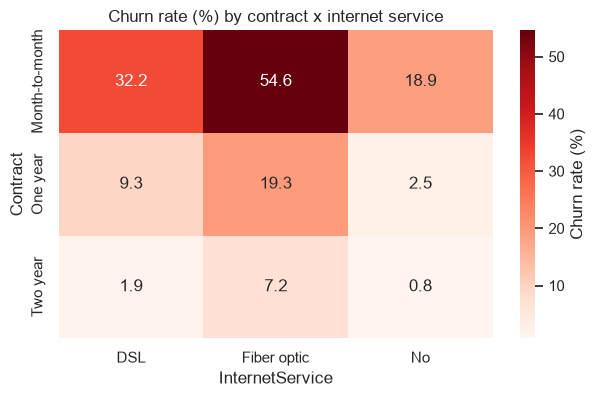

In [14]:
# Churn rate by contract x internet service: find high-revenue, high-churn pockets
pivot = df.pivot_table(index='Contract', columns='InternetService', values='churn_flag', aggfunc='mean', observed=True) * 100
print(pivot.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Reds', ax=ax, cbar_kws={'label': 'Churn rate (%)'})
ax.set_title('Churn rate (%) by contract x internet service')
savefig(fig, 'churn_contract_internet_heatmap.png')
plt.show()

## 10. Statistical reasoning (Phase 3)

Tests are chosen by data type and used only on relationships with business questions behind them:

- **Categorical vs churn:** chi-square test of independence (expected frequencies all > 5, checked below).
- **Numeric vs churn:** Welch's t-test (does not assume equal variance) plus the descriptive effect size; the large sample makes even tiny differences significant, so effect sizes and business materiality are reported alongside p-values.

Significance here means *statistical association*, not causation.

In [15]:
alpha = 0.05
print('Chi-square tests of independence (categorical vs churn):')
cat_tests = {}
for col in ['Contract', 'PaymentMethod', 'InternetService', 'PaperlessBilling', 'gender',
            'SeniorCitizen', 'Partner', 'Dependents', 'OnlineSecurity', 'TechSupport', 'PhoneService']:
    ct = pd.crosstab(df[col], df['Churn'])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    cat_tests[col] = {'chi2': chi2, 'p': p, 'dof': dof, 'cramers_v': cramers_v,
                      'min_expected': expected.min()}
    print(f"  {col:<18} chi2={chi2:8.1f} dof={dof} p={p:.2e} CramersV={cramers_v:.3f} min_expected={expected.min():.1f}")

Chi-square tests of independence (categorical vs churn):
  Contract           chi2=  1184.6 dof=2 p=5.86e-258 CramersV=0.410 min_expected=390.9
  PaymentMethod      chi2=   648.1 dof=3 p=3.68e-140 CramersV=0.303 min_expected=403.9
  InternetService    chi2=   732.3 dof=2 p=9.57e-160 CramersV=0.322 min_expected=405.0
  PaperlessBilling   chi2=   258.3 dof=1 p=4.07e-58 CramersV=0.191 min_expected=762.1
  gender             chi2=     0.5 dof=1 p=4.87e-01 CramersV=0.008 min_expected=925.6
  SeniorCitizen      chi2=   159.4 dof=1 p=1.51e-36 CramersV=0.150 min_expected=303.1
  Partner            chi2=   158.7 dof=1 p=2.14e-36 CramersV=0.150 min_expected=902.8
  Dependents         chi2=   189.1 dof=1 p=4.92e-43 CramersV=0.164 min_expected=559.9
  OnlineSecurity     chi2=   850.0 dof=2 p=2.66e-185 CramersV=0.347 min_expected=405.0
  TechSupport        chi2=   828.2 dof=2 p=1.44e-180 CramersV=0.343 min_expected=405.0
  PhoneService       chi2=     0.9 dof=1 p=3.39e-01 CramersV=0.011 min_expecte

In [16]:
print("Welch's t-tests (numeric vs churn):")
num_tests = {}
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    a = df.loc[df['churn_flag'] == 1, col]
    b = df.loc[df['churn_flag'] == 0, col]
    t_stat, p = stats.ttest_ind(a, b, equal_var=False)
    pooled_sd = np.sqrt((a.var() + b.var()) / 2)
    d = (b.mean() - a.mean()) / pooled_sd  # Cohen's d, non-churn minus churn
    num_tests[col] = {'t': t_stat, 'p': p, 'mean_churn': a.mean(), 'mean_no_churn': b.mean(), 'cohens_d': d}
    print(f"  {col:<15} t={t_stat:8.2f} p={p:.2e} | churn mean={a.mean():9.2f} no-churn mean={b.mean():9.2f} | Cohen's d={d:.2f}")

# Sanity note on normality: t-test is robust at this sample size (n=7043), but report
# the rank-based alternative as corroboration.
u, p_mw = stats.mannwhitneyu(df.loc[df['churn_flag'] == 1, 'tenure'], df.loc[df['churn_flag'] == 0, 'tenure'])
print(f'\nCorroboration (Mann-Whitney U on tenure): U={u:.0f}, p={p_mw:.2e} — same conclusion.')

Welch's t-tests (numeric vs churn):
  tenure          t=  -34.82 p=1.20e-232 | churn mean=    17.98 no-churn mean=    37.57 | Cohen's d=0.89
  MonthlyCharges  t=   18.41 p=8.59e-73 | churn mean=    74.44 no-churn mean=    61.27 | Cohen's d=-0.47
  TotalCharges    t=  -18.71 p=5.90e-75 | churn mean=  1531.80 no-churn mean=  2549.91 | Cohen's d=0.48

Corroboration (Mann-Whitney U on tenure): U=2515538, p=2.42e-208 — same conclusion.


## 11. Key findings (all computed above)

Summarized with exact evidence; every statement is an association observed in this dataset.

In [17]:
summary = []
summary.append(f"Overall churn rate: {df['churn_flag'].mean():.1%} ({int(df['churn_flag'].sum()):,} of {len(df):,} customers).")
ct = churn_table('Contract')
summary.append(f"Contract: month-to-month churn rate {ct.loc['Month-to-month', 'churn_rate']:.1%} vs one-year {ct.loc['One year', 'churn_rate']:.1%} and two-year {ct.loc['Two year', 'churn_rate']:.1%}.")
summary.append(f"Tenure: 0-6 month customers churn at {churn_table('tenure_band').loc['0-6 mo', 'churn_rate']:.1%}; 49-72 month customers at {churn_table('tenure_band').loc['49-72 mo', 'churn_rate']:.1%}.")
pm = churn_table('PaymentMethod')
summary.append(f"Payment: electronic-check customers churn at {pm.loc['Electronic check', 'churn_rate']:.1%} vs automatic bank transfer {pm.loc['Bank transfer (automatic)', 'churn_rate']:.1%}.")
inet = churn_table('InternetService')
summary.append(f"Internet: fiber-optic customers churn at {inet.loc['Fiber optic', 'churn_rate']:.1%} vs DSL {inet.loc['DSL', 'churn_rate']:.1%}.")
sec = services.pivot(index='service', columns='has_service', values='churn_rate')
summary.append(f"Add-ons: internet customers without OnlineSecurity churn at {sec.loc['OnlineSecurity', 'No']:.1%} vs {sec.loc['OnlineSecurity', 'Yes']:.1%} with it; same direction for TechSupport ({sec.loc['TechSupport', 'No']:.1%} vs {sec.loc['TechSupport', 'Yes']:.1%}).")
summary.append(f"Charges: churners pay higher monthly charges on average ({num_tests['MonthlyCharges']['mean_churn']:.2f} vs {num_tests['MonthlyCharges']['mean_no_churn']:.2f}); churners have far lower total charges ({num_tests['TotalCharges']['mean_churn']:.0f} vs {num_tests['TotalCharges']['mean_no_churn']:.0f}) because most are early-tenure customers.")
summary.append(f"Demographics: senior citizens churn at {churn_table('SeniorCitizen').loc[1, 'churn_rate']:.1%} vs {churn_table('SeniorCitizen').loc[0, 'churn_rate']:.1%}; gender shows no material difference ({churn_table('gender').loc['Female', 'churn_rate']:.1%} vs {churn_table('gender').loc['Male', 'churn_rate']:.1%}).")
summary.append(f"Revenue exposure: month-to-month customers generate {combo.loc['Month-to-month', 'monthly_revenue']:,.0f}/mo of revenue and account for {combo.loc['Month-to-month', 'churned_monthly_revenue'] / combo['churned_monthly_revenue'].sum():.0%} of currently churning monthly revenue.")
summary.append(f"High-value customers (top-quartile MonthlyCharges >= {q75:.2f}) churn at {seg.loc[True, 'churn_rate']:.1%} while producing {seg.loc[True, 'monthly_revenue']:,.0f}/mo.")

for s in summary:
    print('-', s)

print('\nStatistical evidence: all tested categorical features except gender and PhoneService are significant')
sig = [c for c, r in cat_tests.items() if r['p'] < alpha]
nonsig = [c for c, r in cat_tests.items() if r['p'] >= alpha]
print('  significant (p<0.05):', ', '.join(sig))
print('  NOT significant:', ', '.join(nonsig) if nonsig else 'none')
print('  strongest associations by Cramers V:', sorted(((c, round(r["cramers_v"], 3)) for c, r in cat_tests.items()), key=lambda x: -x[1])[:4])
print('  numeric: tenure, MonthlyCharges, TotalCharges all differ significantly between churn groups (p<0.001).')

- Overall churn rate: 26.5% (1,869 of 7,043 customers).
- Contract: month-to-month churn rate 42.7% vs one-year 11.3% and two-year 2.8%.
- Tenure: 0-6 month customers churn at 52.9%; 49-72 month customers at 9.5%.
- Payment: electronic-check customers churn at 45.3% vs automatic bank transfer 16.7%.
- Internet: fiber-optic customers churn at 41.9% vs DSL 19.0%.
- Add-ons: internet customers without OnlineSecurity churn at 41.8% vs 14.6% with it; same direction for TechSupport (41.6% vs 15.2%).
- Charges: churners pay higher monthly charges on average (74.44 vs 61.27); churners have far lower total charges (1532 vs 2550) because most are early-tenure customers.
- Demographics: senior citizens churn at 41.7% vs 23.6%; gender shows no material difference (26.9% vs 26.2%).
- Revenue exposure: month-to-month customers generate 257,294/mo of revenue and account for 87% of currently churning monthly revenue.
- High-value customers (top-quartile MonthlyCharges >= 89.85) churn at 32.7% while pr

**Business implications (associations, not causes):**

1. Month-to-month contracts are the dominant churn pocket — both by churn rate and by share of churning monthly revenue. Any retention program should start there.
2. The first year is the danger window: churn is concentrated in the 0–12 month tenure bands.
3. Electronic-check billing and fiber-optic internet are both strongly associated with churn — these are actionable markers for a watch-list.
4. Add-on services (especially OnlineSecurity and TechSupport) are associated with much lower churn among internet customers — bundled customers look stickier.
5. High-value customers churn at a meaningful rate, so churn among the top quartile destroys disproportionate revenue; the model-based revenue-at-risk analysis will quantify this.

These signals feed the feature-engineering and modeling phases; the model will weigh them jointly rather than one at a time.